# 02 – Unsupervised view of the training trucks: PCA and KMeans

**Course topic 09.11:** dimensionality reduction and clustering. **Question:** if we ignore all labels, what structure do the
23,550 training trucks show (one row per truck = its last readout, the same 239 inputs as the supervised model), and does it
have anything to do with repairs?

*Labels are used only afterwards to colour the map and to cross-tabulate clusters. Logic lives in
`src/failsense/analysis/unsupervised.py`; this notebook only calls it. Only the TRAINING split is read.*

In [1]:
import logging

import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.cluster import KMeans

from failsense.analysis import unsupervised as uns
from failsense.config import load_config, resolve_path
from failsense.models.validation_data import registry_input_columns

logging.basicConfig(level=logging.WARNING)
pd.set_option("display.width", 140)
config = load_config()
reports = resolve_path(config["paths"]["reports"])
SEED = config["seed"]

2026/11/09 09:45:40 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at <repo>/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## 1. One row per truck

In [2]:
features, truth = uns.load_truck_data(config)
matrix = uns.select_inputs(features, registry_input_columns(config))
print(matrix.shape, "inputs (no label, no vehicle_id)")
rep = truth["in_study_repair"]
print("repaired trucks:", int(rep.sum()), f"({rep.mean():.1%})")

(23550, 239) inputs (no label, no vehicle_id)
repaired trucks: 2272 (9.6%)


## 2. PCA

Pipeline = impute (median) → `log1p` of the raw counters/bins → standardise → one-hot specs → PCA. All inside one sklearn
`Pipeline`. Why `log1p`: the counters are cumulative and right-skewed, a few extreme trucks would otherwise own the first components.

In [3]:
full = uns.build_embedding_pipeline(matrix, n_components=None, seed=SEED).fit(matrix)
variance = uns.variance_table(full.named_steps["pca"])
display(variance.head(10).round(4))
cfg = config["unsupervised"]
n_keep = int(np.searchsorted(variance["cumulative"], cfg["variance_kept"]) + 1)
print(f"{n_keep} components are needed for {cfg['variance_kept']:.0%} of the variance")

,component,explained,cumulative
0,1,0.2236,0.2236
1,2,0.1496,0.3732
2,3,0.0755,0.4487
3,4,0.0400,0.4887
4,5,0.0294,0.5181
5,6,0.0258,0.5439
6,7,0.0239,0.5678
7,8,0.0214,0.5892
8,9,0.0205,0.6096
9,10,0.0186,0.6282


50 components are needed for 90% of the variance


In [4]:
# Robustness: without log1p the first two components explain much less
raw = uns.build_embedding_pipeline(matrix, n_components=2, seed=SEED, log1p=False).fit(matrix)
print("with log1p   :", full.named_steps["pca"].explained_variance_ratio_[:2].round(3))
print("without log1p:", raw.named_steps["pca"].explained_variance_ratio_.round(3))

with log1p   : [0.224 0.15 ]
without log1p: [0.147 0.108]


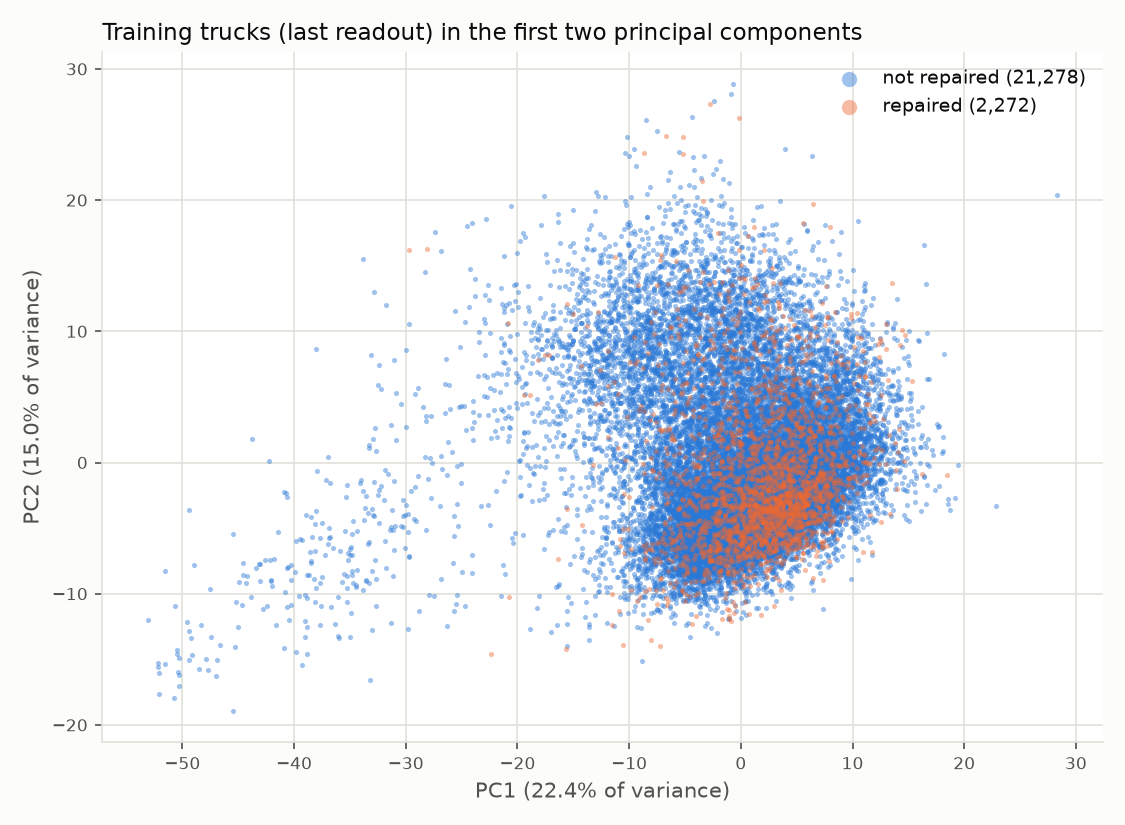

In [5]:
pipe = uns.build_embedding_pipeline(matrix, n_components=n_keep, seed=SEED).fit(matrix)
z = pipe.transform(matrix)
repaired = truth["in_study_repair"].to_numpy(dtype=int)
explained = variance["explained"].to_numpy()
uns.plot_pca_map(z, repaired, explained, reports / "unsupervised_pca_map.png")
display(Image(reports / "unsupervised_pca_map.png"))

**Reading the map:** the repaired trucks (orange) lie inside the dense blob of the non-repaired ones. The first two components
(37 % of the variance together) do **not** separate them. PC1 is dominated by the cumulative counters and the large histograms
(truck age / usage), PC2 by histogram shapes (below).

In [6]:
for i in range(2):
    print(f"PC{i + 1}")
    display(uns.top_loadings(pipe, i, n=8).round(3))

PC1


,feature,weight
0,num_log1p__158_6,0.132
1,num_log1p__158_5,0.131
2,num_log1p__427_0,0.128
3,num_log1p__158_7,0.128
4,num_log1p__397_26,0.126
5,num_log1p__171_0,0.126
6,num_log1p__835_0,0.125
7,num_log1p__459_12,0.125


PC2


,feature,weight
0,num__167_4__share,0.140
1,num__459__mean_bin,-0.138
2,num__459_6__share,0.132
3,num__459_7__share,0.130
4,num__291_10__share,-0.130
5,num__459_5__share,0.129
6,num_log1p__272_3,0.128
7,num__459_4__share,0.127


## 3. KMeans on the 90 %-variance PCA space

`silhouette_score` needs all pairwise distances (O(n²)); `sample_size=5000` evaluates it on a fixed random subsample.

,k,inertia,silhouette
0,2,4.274501e+06,0.2691
1,3,3.840546e+06,0.1240
2,4,3.517282e+06,0.1324
3,5,3.356101e+06,0.1002
4,6,3.239252e+06,0.0924
5,8,3.077514e+06,0.0801
6,10,2.949003e+06,0.0778


best k by silhouette: 2


1 [0.265, 0.126, 0.139]


2 [0.264, 0.13, 0.137]


3 [0.274, 0.128, 0.136]


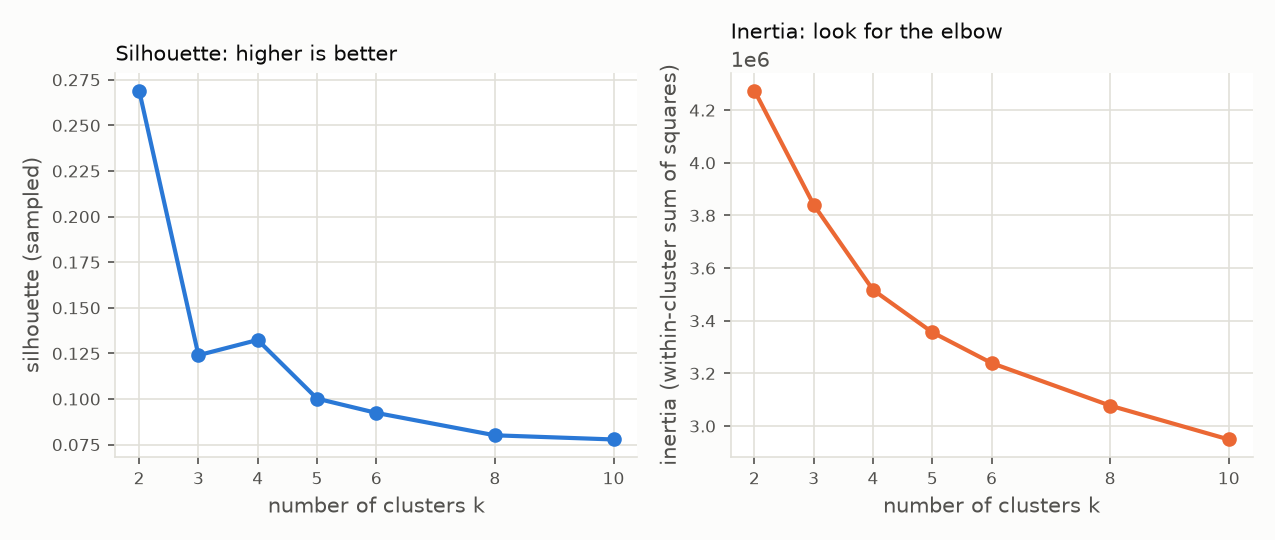

In [7]:
cfg = config["unsupervised"]
scan = uns.kmeans_scan(z, cfg["ks"], cfg["silhouette_sample_size"], SEED)
display(scan.round(4))
k = uns.best_k(scan)
print("best k by silhouette:", k)
# Stability: same scan with other seeds (KMeans start and silhouette subsample)
for seed in (1, 2, 3):
    print(seed, uns.kmeans_scan(z, [2, 3, 4], 5000, seed)["silhouette"].round(3).tolist())
uns.plot_k_scan(scan, reports / "unsupervised_k_scan.png")
display(Image(reports / "unsupervised_k_scan.png"))

A silhouette around 0.27 for k=2 and ≈ 0.1 for k ≥ 3 means **weak structure** (a common rule of thumb: > 0.5 clear, 0.25–0.5 weak,
< 0.25 essentially none). There is one dominant split into two groups and no further natural clusters.

## 4. What are the clusters, and are they related to repairs?

,cluster,n_trucks,n_repaired,repair_rate,ci_low,ci_high,lift
0,0,4840,262,0.0541,0.0481,0.0609,0.5611
1,1,18710,2010,0.1074,0.1031,0.1119,1.1135


normalised mutual information cluster vs repaired: 0.0073


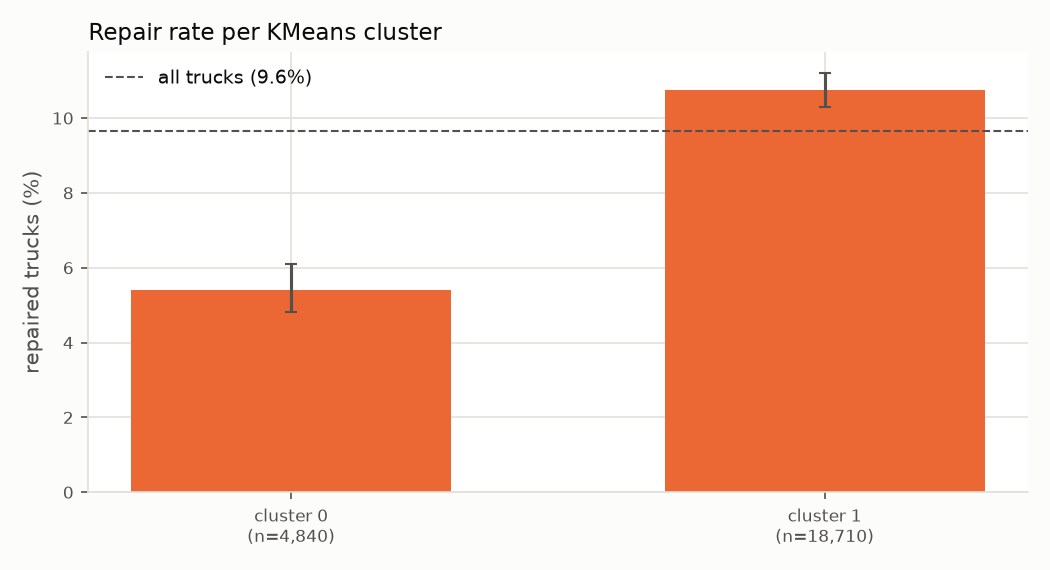

In [8]:
clusters = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(z)
summary = uns.cluster_summary(clusters, truth)
display(summary.round(4))
nmi = uns.cluster_agreement(clusters, truth)
print("normalised mutual information cluster vs repaired:", round(nmi, 4))
base_rate = float(truth["in_study_repair"].mean())
uns.plot_cluster_repair_rate(summary, base_rate, reports / "unsupervised_clusters.png")
display(Image(reports / "unsupervised_clusters.png"))

In [9]:
profile = uns.spec_profile(clusters, features, top=3)
shares = profile.pivot_table(index=["spec", "category"], columns="cluster", values="share")
display(shares.round(2).head(12))
display(features.assign(cluster=clusters).groupby("cluster")[["time_step", "171_0"]].median())

cluster             0     1
spec   category            
Spec_0 Cat0      0.50  0.90
       Cat1      0.50  0.10
       Cat2      0.01  0.00
Spec_1 Cat0      0.08  0.07
       Cat1      0.22  0.66
       Cat2      0.02  0.05
Spec_2 Cat0      0.31  0.09
       Cat1      0.21  0.71
       Cat2      0.08  0.12
Spec_3 Cat0      0.41  0.67
       Cat1      0.03  0.26
       Cat2      0.27  0.05

,time_step,171_0
cluster,,
0,188.3,1918867.5
1,220.4,5764822.5


## 5. Conclusions (honest)

* The 239 inputs are high-dimensional: 50 components are needed for 90 % of the variance, the first two carry 37 %.
* The two KMeans clusters are mostly a **truck configuration split** (e.g. `Spec_0 = Cat0` in 90 % of cluster 1 vs 50 % in cluster 0),
  not a wear or failure split. The repair rate differs (5.4 % vs 10.7 %), but the normalised mutual information with the repaired
  flag is 0.007: clustering alone says almost nothing about repairs.
* So unsupervised grouping does **not** replace the supervised model. It is useful as a descriptive tool (fleet segments) and as a
  sanity check: an anomaly score (10.11) would have to be tested as an extra feature with a paired comparison.
* Caveat: the last readout of a repaired truck lies just before the repair, the last readout of a non-repaired truck at the end of
  observation; this is not the situation of a random cut-off, so these numbers are descriptive, not predictive performance.